# Assignment 3 · Parte 2 – Mapas del Perú

**Grupo 11** · Diplomado PUCP · Fundamentos de Python

**Pregunta:** ¿En qué zonas del país se concentraron las declaratorias de emergencia por lluvias (1 ene – 31 may 2024) y coinciden con las zonas donde más llovió?

## 1. Cargar los datos y las fronteras

In [1]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

# dtype={"ubigeo": str} evita que '01' se convierta en el número 1
dataset = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})

# Fronteras de los 25 departamentos. El código del departamento viene en la columna FIRST_IDDP
departamentos = gpd.read_file("datos/departamentos.geojson")
departamentos = departamentos.rename(columns={"FIRST_IDDP": "ubigeo"})[["ubigeo", "NOMBDEP", "geometry"]]

print("Sistema de coordenadas:", departamentos.crs)
print("Departamentos en el mapa:", departamentos.shape[0])
departamentos.head(3)

Sistema de coordenadas: EPSG:4326
Departamentos en el mapa: 25


,ubigeo,NOMBDEP,geometry
0,01,AMAZONAS,"POLYGON ((-77.75893 -6.96451, -77.84586 -6.976..."
1,02,ANCASH,"POLYGON ((-77.31749 -8.53015, -77.28903 -8.589..."
2,03,APURIMAC,"POLYGON ((-72.47177 -14.6614, -72.57725 -14.68..."


**Sobre el archivo de fronteras:** usamos `datos/departamentos.geojson` (25 departamentos, columna `FIRST_IDDP` con el ubigeo de 2 dígitos), tomado del repositorio `d2cml-ai/Data-Science-Python`. El de la sesión 7 solo trae el nombre del departamento, sin ubigeo, y no permite cruzar por código.

## 2. Cruce por ubigeo (como texto)

Antes de unir, verificamos que el ubigeo esté escrito igual en los dos lados: texto de 2 dígitos con el cero a la izquierda.

In [2]:
print("Mapa  :", departamentos["ubigeo"].dtype, "| ejemplo:", departamentos["ubigeo"].iloc[0])
print("Tabla :", dataset["ubigeo"].dtype, "| ejemplo:", dataset["ubigeo"].iloc[0])
print("Coinciden:", len(set(departamentos["ubigeo"]) & set(dataset["ubigeo"])), "de", len(dataset))

Mapa  : object | ejemplo: 01
Tabla : object | ejemplo: 01
Coinciden: 25 de 25


In [3]:
# how="left" desde el mapa para no perder ningún departamento.
# indicator=True agrega la columna _merge, que dice si cada fila encontró pareja.
mapa = departamentos.merge(dataset, on="ubigeo", how="left", indicator=True)

# Reporte de no cruces
sin_datos = mapa.loc[mapa["_merge"] == "left_only", "NOMBDEP"].tolist()
sin_mapa = sorted(set(dataset["ubigeo"]) - set(departamentos["ubigeo"]))
print("Departamentos del mapa sin datos:", sin_datos)
print("Ubigeos de la tabla que no están en el mapa:", sin_mapa)

# Comprobación: el total no debe cambiar después del cruce
print("Declaratorias en el mapa :", int(mapa["declaratorias"].sum()))
print("Declaratorias en la tabla:", int(dataset["declaratorias"].sum()))

mapa = mapa.drop(columns="_merge")

Departamentos del mapa sin datos: []
Ubigeos de la tabla que no están en el mapa: []
Declaratorias en el mapa : 100
Declaratorias en la tabla: 100


**Reporte del cruce:** cruzaron los 25 departamentos de 25. No quedó ninguno sin datos ni ningún ubigeo sin mapa, y el total de declaratorias (100) es el mismo antes y después del cruce.

In [4]:
print("Columnas disponibles:")
print(mapa.columns.tolist())

print("\nTotal de departamentos:", len(mapa))
print("Declaratorias totales:", mapa["declaratorias"].sum())
print("Departamentos sin datos:", mapa["declaratorias"].isna().sum())

display(mapa[["ubigeo", "NOMBDEP", "declaratorias"]].head())

Columnas disponibles:
['ubigeo', 'NOMBDEP', 'geometry', 'departamento', 'declaratorias', 'prorrogas', 'capital', 'latitud', 'longitud', 'lluvia_total_mm', 'dias_lluvia_fuerte']

Total de departamentos: 25
Declaratorias totales: 100
Departamentos sin datos: 0


,ubigeo,NOMBDEP,declaratorias
0,01,AMAZONAS,4
1,02,ANCASH,5
2,03,APURIMAC,7
3,04,AREQUIPA,7
4,05,AYACUCHO,7


## 3. Mapas estáticos con Geopandas

### 3.1 Declaratorias de emergencia por departamento

Coropleta por quintiles (`scheme="Quantiles"`, `k=5`). Usamos la misma escala de amarillos a rojos que en el mapa interactivo.

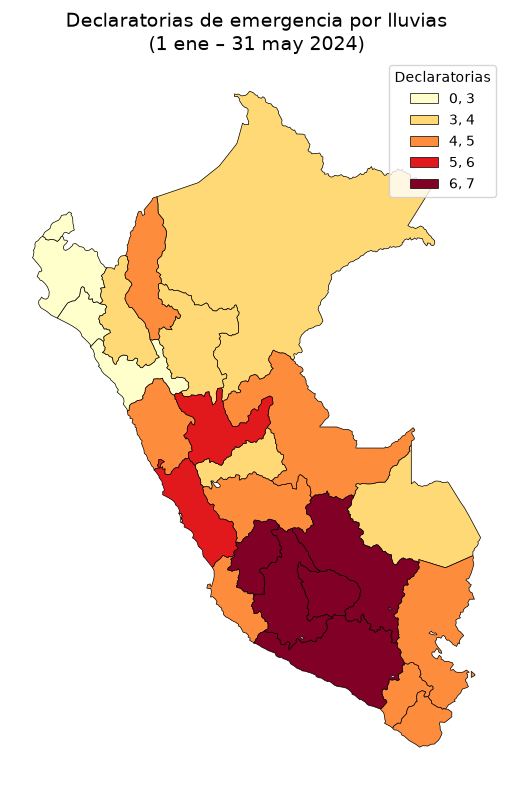

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))

mapa.plot(
    column="declaratorias",
    cmap="YlOrRd",
    scheme="Quantiles",
    k=5,
    legend=True,
    legend_kwds={"title": "Declaratorias", "fmt": "{:.0f}"},
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title(
    "Declaratorias de emergencia por lluvias\n(1 ene – 31 may 2024)",
    fontsize=14
)
ax.axis("off")

plt.tight_layout()
plt.show()

### 3.2 Lluvia acumulada en la capital de cada departamento

Antes aquí iba el porcentaje de declaratorias. Pero el total es exactamente 100, así que el porcentaje
era el mismo número que el conteo y salía un mapa idéntico al anterior. En su lugar mapeamos la lluvia,
que es la otra mitad de nuestra pregunta.

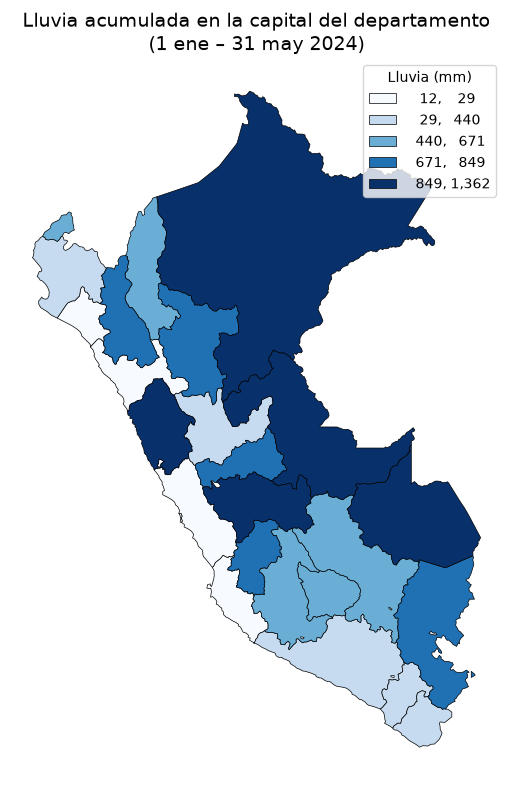

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))

mapa.plot(
    column="lluvia_total_mm",
    cmap="Blues",
    scheme="Quantiles",
    k=5,
    legend=True,
    legend_kwds={"title": "Lluvia (mm)", "fmt": "{:,.0f}"},
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    ax=ax
)

ax.set_title(
    "Lluvia acumulada en la capital del departamento\n(1 ene – 31 may 2024)",
    fontsize=14
)
ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Mapa interactivo con Folium

Al pasar el cursor sobre un departamento, el tooltip muestra su nombre, sus declaratorias y la lluvia en su capital.

La salida de la celda del mapa se limpió antes de guardar, para no aumentar el peso del repositorio.
El mapa interactivo queda guardado en `mapa_departamental.html`.

In [7]:
mapa_folium = mapa.to_crs(epsg=4326).copy()

In [8]:
m = folium.Map(
    location=[-9.19, -75.015],
    zoom_start=5,
    tiles="CartoDB positron"
)

C:\Users\USUARIO\Documents\CIENCIA DE DATOS\CLASES PYTHON\Assignment1\assignment_1\assignment_3\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [9]:
folium.Choropleth(
    geo_data=mapa_folium,
    data=mapa_folium,
    columns=["ubigeo", "declaratorias"],
    key_on="feature.properties.ubigeo",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.4,
    legend_name="Total de declaratorias",
    nan_fill_color="lightgrey"
).add_to(m)

folium.GeoJson(
    mapa_folium,
    # Capa transparente: solo sirve para el tooltip. Sin este estilo, Folium la
    # pinta de azul encima de la coropleta y cambia los colores.
    style_function=lambda feature: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["NOMBDEP", "declaratorias", "lluvia_total_mm"],
        aliases=["Departamento:", "Declaratorias:", "Lluvia en la capital (mm):"],
        localize=True
    ),
    name="Información departamental"
).add_to(m)

folium.LayerControl().add_to(m)

m

In [10]:
m.save("mapa_departamental.html")

## 5. Patrón geográfico

- **Las declaratorias se concentran en la sierra sur.** Huancavelica, Apurímac, Ayacucho, Cusco y Arequipa forman un bloque continuo y son los cinco departamentos con el máximo de 7 declaratorias.
- **La costa norte no tuvo declaratorias.** Tumbes, Piura y Lambayeque, junto con el Callao, no recibieron ninguna en la temporada.
- **La lluvia se concentra en el oriente, no en la sierra sur.** Loreto (1,362 mm), Madre de Dios (1,150 mm) y Ucayali (887 mm) están entre los más lluviosos, pero recibieron solo 3, 3 y 4 declaratorias.
- **Ojo con la costa centro-sur:** Lima, Ica, Moquegua y Tacna registran menos de 50 mm en su capital y aun así tuvieron entre 4 y 6 declaratorias. La lluvia se mide en la capital, que es una ciudad costera, y no refleja lo que llueve en sus provincias andinas.

En resumen, el mapa de declaratorias y el de lluvia no coinciden, lo que es coherente con la correlación cercana a 0 de la Parte 1.